## This notebook processes the Kang dataset after Kang_Data.ipynb files and generates the graphs and necessary files for subsequent model training.

In [4]:
import scanpy as sc 
import pandas as pd
import SEACells
import numpy as np
import matplotlib
from statistics import mode
import matplotlib.pyplot as plt
import seaborn as sns
import sys 
sys.path.insert(0, '../')
import utils
from importlib import reload
reload(utils)
from utils import *
# Some plotting aesthetics
%matplotlib inline

sns.set_style('ticks')
matplotlib.rcParams['figure.figsize'] = [4, 4]
matplotlib.rcParams['figure.dpi'] = 100

# Input Data Directory
data_path = 'E:\\VSCODE\\PrePR-CT\\Data\\'
# Output Results Directory
save_path_results = "E:\\VSCODE\\PrePR-CT\\Results\\"


## Import the data

In [5]:
adata = sc.read(data_path+'Kang.h5ad')
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'cov_cond'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'cell_type_colors', 'condition_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## Constructing cell type graphs over control cells 

In [6]:
ctrl_data = adata[adata.obs.condition == 'control'].copy()
ctrl_data.obs.cell_type.value_counts()

cell_type
CD4 T cells          5242
CD14+ Monocytes      2828
B cells              1329
CD8 T cells          1096
NK cells              933
FCGR3A+ Monocytes     753
Dendritic cells       207
Name: count, dtype: int64

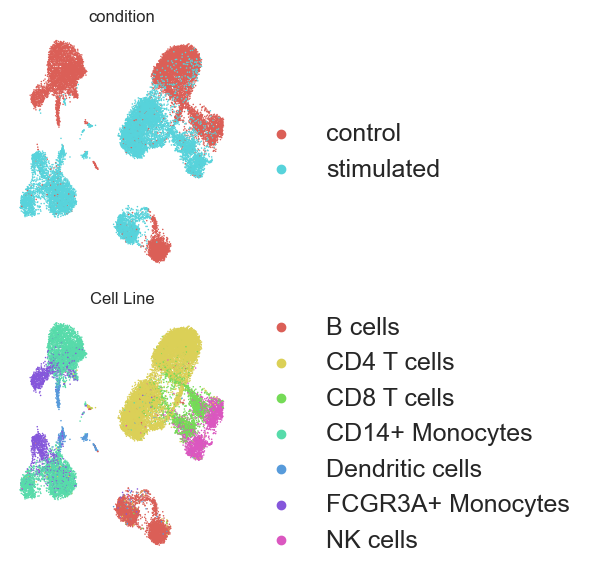

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

fig, axes = plt.subplots(nrows=2, figsize=(6, 6))

# Plot UMAP colored by condition — remove title
sc.pl.umap(
    adata=adata,
    color=["condition"],
    legend_fontsize=18,
    ax=axes[0],
    title=None,  # Remove title
    show=False,
    palette=sns.color_palette("hls", 2),
    frameon=False
)

# Plot UMAP colored by cell type with font size 16
sc.pl.umap(
    adata=adata,
    color=["cell_type"],
    legend_fontsize=18,
    ax=axes[1],
    title="Cell Line",  # Optional: keep or remove
    show=False,
    palette=sns.color_palette("hls", len(adata.obs['cell_type'].unique())),
    frameon=False
)

# Apply font size 16 to axis tick labels manually (optional enhancement)
for ax in axes:
    ax.tick_params(labelsize=16)

# Adjust spacing and save
plt.tight_layout()
plt.savefig("Kang_umap.pdf", bbox_inches='tight', dpi=300)
plt.show()


In [8]:
ctrl_data.obs.cell_type.value_counts()

cell_type
CD4 T cells          5242
CD14+ Monocytes      2828
B cells              1329
CD8 T cells          1096
NK cells              933
FCGR3A+ Monocytes     753
Dendritic cells       207
Name: count, dtype: int64

In [9]:
n_SEACells  = int(len(ctrl_data) / 50)
print(n_SEACells)
build_kernel_on = 'X_pca' # key in ad.obsm to use for computing metacells
                          # This would be replaced by 'X_svd' for ATAC data

## Additional parameters
n_waypoint_eigs = 10 # Number of eigenvalues to consider when initializing metacells

247


## Run SEACells over the control data.

In [10]:
model = SEACells.core.SEACells(ctrl_data, 
                  build_kernel_on=build_kernel_on, 
                  n_SEACells=n_SEACells, 
                  n_waypoint_eigs=n_waypoint_eigs,
                  convergence_epsilon = 1e-5)

Welcome to SEACells!


In [11]:
model.construct_kernel_matrix()
M = model.kernel_matrix


Computing kNN graph using scanpy NN ...
Computing radius for adaptive bandwidth kernel...


  0%|          | 0/12388 [00:00<?, ?it/s]

Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


  0%|          | 0/12388 [00:00<?, ?it/s]

Building similarity LIL matrix...


  0%|          | 0/12388 [00:00<?, ?it/s]

Constructing CSR matrix...


In [12]:
# Initialize archetypes
model.initialize_archetypes()

Building kernel on X_pca
Computing diffusion components from X_pca for waypoint initialization ... 
Done.
Sampling waypoints ...
Done.
Selecting 229 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████| 28/28 [00:00<00:00, 57.04it/s]

Selecting 18 cells from greedy initialization.


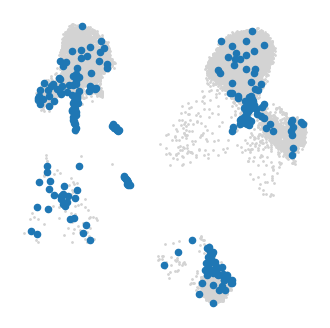

In [13]:
# Plot the initilization to ensure they are spread across phenotypic space
SEACells.plot.plot_initialization(ctrl_data, model)

In [14]:
model.fit(min_iter=10, max_iter=100)

Randomly initialized A matrix.
Setting convergence threshold at 0.00205
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Starting iteration 50.
Completed iteration 50.
Starting iteration 60.
Completed iteration 60.
Converged after 64 iterations.


In [15]:
# You can force the model to run additional iterations step-wise using the .step() function
print(f'Ran for {len(model.RSS_iters)} iterations')
for _ in range(5):
    model.step()
print(f'Ran for {len(model.RSS_iters)} iterations')

Ran for 65 iterations
Ran for 70 iterations


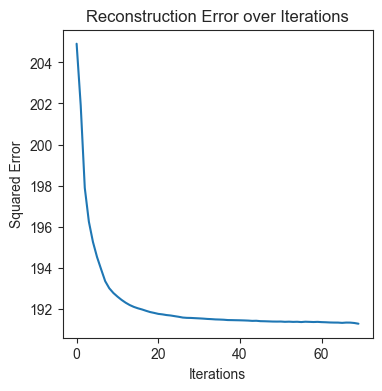

In [17]:
# Check for convergence 
model.plot_convergence()

In [18]:
ctrl_data.obs[['SEACell']].head()
ctrl_data.obs.cell_type

index
AAACATACATTTCC-1        CD14+ Monocytes
AAACATACCAGAAA-1        CD14+ Monocytes
AAACATACCATGCA-1            CD4 T cells
AAACATACCTCGCT-1        CD14+ Monocytes
AAACATACCTGGTA-1        Dendritic cells
                            ...        
TTCTGATGTCTCGC-1-1          CD4 T cells
TTGGAGTGCTCGAA-1-1          CD4 T cells
TTTAGCTGCGAACT-1-1          CD4 T cells
TTTATCCTGCGAGA-1-1    FCGR3A+ Monocytes
TTTATCCTGGAAAT-1-1      CD14+ Monocytes
Name: cell_type, Length: 12388, dtype: category
Categories (7, object): ['B cells', 'CD4 T cells', 'CD8 T cells', 'CD14+ Monocytes', 'Dendritic cells', 'FCGR3A+ Monocytes', 'NK cells']

In [42]:
ctrl_data.obs[['SEACell']].head()

,SEACell
AAACATACATTTCC-1,SEACell-44
AAACATACCAGAAA-1,SEACell-9
AAACATACCATGCA-1,SEACell-54
AAACATACCTCGCT-1,SEACell-218
AAACATACCTGGTA-1,SEACell-237


In [19]:
adata.obs['SEACell'] = 'None'
adata.obs.loc[ctrl_data.obs.index.tolist(), 'SEACell'] = ctrl_data.obs['SEACell'].values

In [20]:
ctrl_data.layers['X'] = ctrl_data.X

## Summarize SEACells by cell type label

In [3]:
SEACell_soft_ad = SEACells.core.summarize_by_soft_SEACell(ctrl_data,  model.A_, 
                                                          celltype_label='cell_type', summarize_layer = 'counts', minimum_weight = 0.05)
SEACell_soft_ad.X.A

NameError: name 'SEACells' is not defined

In [23]:
SEACell_soft_ad.obs

,Pseudo-sizes,celltype,celltype_purity
0,45.961901,CD14+ Monocytes,0.994180
1,38.855313,B cells,0.899204
2,58.429045,CD4 T cells,0.512941
3,42.818532,B cells,1.000000
4,76.561998,CD14+ Monocytes,0.954501
...,...,...,...
242,74.525357,CD4 T cells,0.980642
243,18.645921,CD4 T cells,1.000000
244,76.296215,CD4 T cells,0.984511
245,10.125430,Dendritic cells,0.970077


In [24]:
SEACell_soft_ad.obs
SEACell_soft_ad.obs.rename({"celltype": "cell_type"}, axis=1, inplace=True)

In [25]:
SEACell_soft_ad.obs.cell_type.value_counts()

cell_type
CD4 T cells          83
CD14+ Monocytes      61
B cells              41
FCGR3A+ Monocytes    18
Dendritic cells      16
CD8 T cells          15
NK cells             13
Name: count, dtype: int64

In [26]:
SEACell_soft_ad.write(data_path+'SEACell_soft_ad_Kang.h5ad')

In [27]:
adata.write(data_path+'Kang.h5ad')

In [28]:
SEACell_soft_ad = sc.read(data_path+'SEACell_soft_ad_Kang.h5ad')
SEACell_soft_ad

AnnData object with n_obs × n_vars = 247 × 5000
    obs: 'Pseudo-sizes', 'cell_type', 'celltype_purity'

In [29]:
SEACell_soft_ad.obs.cell_type.value_counts()

cell_type
CD4 T cells          83
CD14+ Monocytes      61
B cells              41
FCGR3A+ Monocytes    18
Dendritic cells      16
CD8 T cells          15
NK cells             13
Name: count, dtype: int64

## Construct co-expression graphs using SEACells generated from the control data.

In [30]:
import os
import networkx as nx
from torch_geometric.utils.convert import from_networkx
from sklearn.metrics import mean_squared_error
from torch_geometric.data import InMemoryDataset, Data, download_url, extract_zip, HeteroData, Batch
from torch_geometric.utils import *
import torch
from torch import nn
cell_type_network = {}
# Leaf directory 
directory = "Kang"
# Parent Directories 
parent_dir = "/ibex/scratch/alsulara/PrePR-CT/graphs/"
# Path 
path = os.path.join(parent_dir, directory)
print(path)
try: 
    os.makedirs(path) 
except:
    print("File exists!")
max_nodes = 0
genes_pos = []
for cell_type in SEACell_soft_ad.obs.cell_type.unique():
    print(cell_type)
    cell = Correlation_matrix(SEACell_soft_ad, cell_type, 'cell_type',
                       hv_genes_cells = None, union_HVGs = True)
    threshold = np.percentile(np.abs(cell[0].values), 99.0)
    print("threshold:", threshold)
    g = create_coexpression_graph(SEACell_soft_ad, cell, cell_type, threshold, 'gene_name')
    if g.num_nodes >= max_nodes:
        max_nodes = g.num_nodes
    cell_type_network[cell_type] = g
    genes_pos.append(cell_type_network[cell_type].pos)
    cell_type_network[cell_type].pos = torch.tensor(cell_type_network[cell_type].pos)
    torch.save(cell_type_network[cell_type] , os.path.join(path,cell_type+'_coexpr_graph.pkl'))
cell_type_network    

/ibex/scratch/alsulara/PrePR-CT/graphs/Kang
CD14+ Monocytes


e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


threshold: 0.5829044932941768
number_of_edges before the threshold (5000 x 5000):  25000000
number_of_edges after the threshold:  250001
number_of_edges after removing self loops:  246168
final number_of_edges:  246168
B cells


e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


threshold: 0.6798624916926878
number_of_edges before the threshold (5000 x 5000):  25000000
number_of_edges after the threshold:  250001
number_of_edges after removing self loops:  246080
final number_of_edges:  246080
CD4 T cells


...

e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


threshold: 0.7062164710299833
number_of_edges before the threshold (5000 x 5000):  25000000
number_of_edges after the threshold:  250001
number_of_edges after removing self loops:  246660
final number_of_edges:  246660
FCGR3A+ Monocytes


e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


threshold: 0.5982388837201273
number_of_edges before the threshold (5000 x 5000):  25000000
number_of_edges after the threshold:  250000
number_of_edges after removing self loops:  246694
final number_of_edges:  246694


{'CD14+ Monocytes': Data(x=[3355, 61], edge_index=[2, 246168], edge_attr=[246168], pos=[3355]),
 'B cells': Data(x=[3095, 41], edge_index=[2, 246080], edge_attr=[246080], pos=[3095]),
 'CD4 T cells': Data(x=[3902, 83], edge_index=[2, 245438], edge_attr=[245438], pos=[3902]),
 'NK cells': Data(x=[3816, 13], edge_index=[2, 246184], edge_attr=[246184], pos=[3816]),
 'CD8 T cells': Data(x=[3960, 15], edge_index=[2, 246016], edge_attr=[246016], pos=[3960]),
 'Dendritic cells': Data(x=[3327, 16], edge_index=[2, 246660], edge_attr=[246660], pos=[3327]),
 'FCGR3A+ Monocytes': Data(x=[3306, 18], edge_index=[2, 246694], edge_attr=[246694], pos=[3306])}

## Check the overlapping genes between the cell type graphs

In [31]:
overlap_df = pd.DataFrame(index = cell_type_network.keys(), columns = cell_type_network.keys())
for key1 in cell_type_network.keys():
    for key2 in cell_type_network.keys():
        overlap_df.loc[key1, key2] = (len(np.intersect1d(cell_type_network[key1].pos, cell_type_network[key2].pos)))

# identify the furthest cell type
indices = np.argsort(overlap_df.values, axis=0)[-7, :]
print(indices)
testing_cell = overlap_df.columns[mode(indices)]
print(testing_cell)
overlap_df

[1 0 1 1 1 1 1]
B cells


,CD14+ Monocytes,B cells,CD4 T cells,NK cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes
CD14+ Monocytes,3355,2394,2772,3004,3059,2768,2769
B cells,2394,3095,2535,2697,2743,2450,2429
CD4 T cells,2772,2535,3902,3078,3218,2739,2720
NK cells,3004,2697,3078,3816,3640,3182,3143
CD8 T cells,3059,2743,3218,3640,3960,3179,3166
Dendritic cells,2768,2450,2739,3182,3179,3327,2990
FCGR3A+ Monocytes,2769,2429,2720,3143,3166,2990,3306


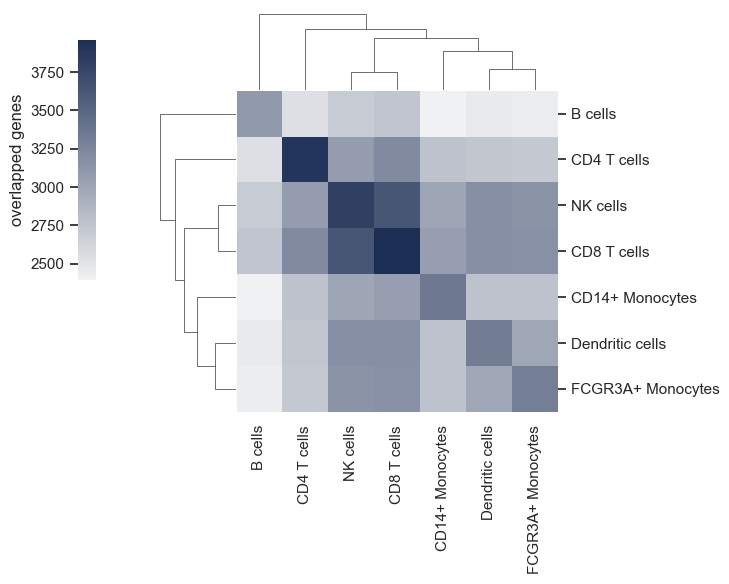

In [32]:
from matplotlib.colors import LinearSegmentedColormap
sns.set()
sns.set_style( {'axes.grid' : False})
import seaborn as sns
cmap = sns.light_palette("#1C2E54", as_cmap=True)
g = sns.clustermap(overlap_df.astype(float), figsize=(6, 6), cmap = cmap
                   , cbar_kws={'label': 'overlapped genes', 'location': 'left'})
g.fig.subplots_adjust(right=0.7)
g.ax_cbar.set_position((-0.1, .52, .03, .4))
plt.savefig(save_path_results+'overlap_matrix_Kang.pdf', bbox_inches='tight')
plt.show()
sns.set()

In [33]:
adata = sc.read(data_path+'Kang.h5ad')
adata.obs["dose_value"] = 1.0
adata.obs['cov_drug'] = adata.obs.cell_type.astype(str) + '_' + adata.obs.condition.astype(str)
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'cov_cond', 'SEACell', 'dose_value', 'cov_drug'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'cell_type_colors', 'condition_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [34]:
print(len(adata.obs.loc[adata.obs.condition == 'control']), len(adata.obs.loc[adata.obs.condition != 'control']))
print(len(adata.obs.loc[adata.obs.condition == 'control']) + len(adata.obs.loc[adata.obs.condition != 'control']))

12388 11861
24249


In [37]:
import os
cell_type_network = {}
# Leaf directory 
directory = "Kang"
# Parent Directories 
parent_dir = "E:\\VSCODE\\PrePR-CT\\Cell-Type-Specific-Graphs-main\\graphs"
# Path 
path = os.path.join(parent_dir, directory)
print(path)
try: 
    os.makedirs(path) 
except:
    print("File exists!")
max_nodes = 0
genes_pos = []
for cell_type in adata.obs.cell_type.unique():
    print(cell_type)
    cell_type_network[cell_type] = torch.load(os.path.join(path,cell_type+'_coexpr_graph.pkl'))
    if cell_type_network[cell_type].num_nodes >= max_nodes:
        max_nodes = cell_type_network[cell_type].num_nodes
print(max_nodes)
cell_type_network

E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main\graphs\Kang
File exists!
CD14+ Monocytes
CD4 T cells
Dendritic cells
NK cells
CD8 T cells
B cells
FCGR3A+ Monocytes
3943


{'CD14+ Monocytes': Data(x=[3401, 62], edge_index=[2, 246140], edge_attr=[246140], pos=[3401]),
 'CD4 T cells': Data(x=[3879, 82], edge_index=[2, 245430], edge_attr=[245430], pos=[3879]),
 'Dendritic cells': Data(x=[3234, 15], edge_index=[2, 246781], edge_attr=[246781], pos=[3234]),
 'NK cells': Data(x=[3801, 13], edge_index=[2, 246186], edge_attr=[246186], pos=[3801]),
 'CD8 T cells': Data(x=[3943, 16], edge_index=[2, 246056], edge_attr=[246056], pos=[3943]),
 'B cells': Data(x=[3176, 41], edge_index=[2, 246080], edge_attr=[246080], pos=[3176]),
 'FCGR3A+ Monocytes': Data(x=[3275, 18], edge_index=[2, 246726], edge_attr=[246726], pos=[3275])}

## Match treatment and control cells using SEACell clusters

In [38]:
stim_data = adata[adata.obs.condition != 'control'].copy()
stim_data.layers['ctrl_x'] = stim_data.X.A
ctrl_data = adata[adata.obs.condition == 'control'].copy()

for cell_type in adata.obs.cell_type.unique():
    genes = cell_type_network[cell_type].pos.tolist()
    cell_type_network[cell_type].x = torch.mean(torch.tensor(ctrl_data[ctrl_data.obs.cell_type == cell_type, genes].copy().X.A), dim = 0)
    std = torch.var(torch.tensor(ctrl_data[ctrl_data.obs.cell_type == cell_type, genes].copy().X.A), dim = 0)
    cell_type_network[cell_type].x = torch.cat([cell_type_network[cell_type].x.unsqueeze(1), std.unsqueeze(1)], dim = 1)    


for cov_drug in tq.tqdm(stim_data.obs.cov_drug.unique()):
    cell_type = cov_drug.split('_')[0]
    ad_ctrl = ctrl_data[ctrl_data.obs.cell_type == cell_type].copy()
    ad_stim = stim_data[stim_data.obs.cov_drug == cov_drug].copy()
    num_samples = len(ad_stim)
    sele_samples = balance_subsample(np.array(ad_ctrl.obs.index.values.tolist()), np.array(ad_ctrl.obs.SEACell.values.tolist()), num_samples)
    stim_data[ ad_stim.obs.index.values,: ].layers['ctrl_x'] = ad_ctrl[sele_samples, :].copy().X.A

  0%|          | 0/7 [00:00<?, ?it/s]

## Construct PyTorch Geometric (PyG) data objects for the cells to enable GNN training.

In [39]:
from importlib import reload
import utils
reload(utils)
from utils import *
cells_train = create_cells(stim_data, cell_type_network, None)

['CD8 T cells', 'Dendritic cells', 'B cells', 'CD4 T cells', 'CD14+ Monocytes', 'NK cells', 'FCGR3A+ Monocytes']
Categories (7, object): ['B cells', 'CD4 T cells', 'CD8 T cells', 'CD14+ Monocytes', 'Dendritic cells', 'FCGR3A+ Monocytes', 'NK cells'] ['stimulated']
Categories (1, object): ['stimulated']


Processing cov_drugs:   0%|          | 0/7 [00:00<?, ?it/s]

Processing CD8 T cells_stimulated samples:   0%|          | 0/937 [00:00<?, ?it/s]

Processing Dendritic cells_stimulated samples:   0%|          | 0/224 [00:00<?, ?it/s]

Processing B cells_stimulated samples:   0%|          | 0/1230 [00:00<?, ?it/s]

Processing CD4 T cells_stimulated samples:   0%|          | 0/5087 [00:00<?, ?it/s]

Processing CD14+ Monocytes_stimulated samples:   0%|          | 0/2512 [00:00<?, ?it/s]

Processing NK cells_stimulated samples:   0%|          | 0/1046 [00:00<?, ?it/s]

Processing FCGR3A+ Monocytes_stimulated samples:   0%|          | 0/825 [00:00<?, ?it/s]

In [40]:
import pickle
with open(data_path+'cells_Kang.pkl', 'wb') as f:
    pickle.dump(cells_train, f)

In [41]:
adata.write(data_path+'Kang.h5ad')
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'cov_cond', 'SEACell', 'dose_value', 'cov_drug'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'cell_type_colors', 'condition_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'